# Time-to-completion experiment: Expected SARSA

Train fresh adaptive and always-on agents to finish a **300 m route** before a
**16 s deadline**. Earlier safe finishes receive more reward. Run top to bottom
with the project's `.venv` kernel. This retains the original sensor model and
linear Expected SARSA, with navigation/clock features for the finite task.

The previous run had 0/12 adaptive crashes and 6/12 learned always-on crashes.
That small comparison does not identify the cause. The old reward already
rewarded speed, but had no finish line. This experiment tests a revised objective;
it does not assume speed incentives will improve safety.


## 1. Setup

Policies use sensor observations, ego telemetry, and normalized remaining route
and deadline (assumed available navigation/clock telemetry). They receive no
traffic truth or weather labels. Route progress is measured along the road's
world x axis relative to the starting position, not cumulative path length.


In [1]:
from pathlib import Path
import sys, os, copy, json
from dataclasses import asdict
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "environments/sensor_highway/env.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook within MORL4AVSO.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from importlib.metadata import version
from environments.sensor_highway import ExperimentConfig
from algorithms.sensor_agent import AgentSettings, ObservationEncoder, LinearExpectedSarsa, FEATURE_SCHEMA
from experiments.agent_helpers import train_agent, evaluate_agents, run_agent
from experiments.notebook_helpers import plot_snapshot
print("Interpreter:", sys.executable)
PACKAGE_VERSIONS = {name: version(name) for name in ["highway-env", "gymnasium", "numpy", "pandas", "matplotlib"]}
print(PACKAGE_VERSIONS)

Interpreter: .venv/bin/python
{'highway-env': '1.12.1', 'gymnasium': '1.4.0', 'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## 2. What the agent learns

The original Q-table stored one estimate for each discrete state/action pair.
Here there are too many possible grid states, so we use a **linear value model**:

`Q(observation, action) = action_weights · observation_features`

Each action has a vector of weights. Features summarize obstacle evidence, free
space evidence, measurement support, age, and radial velocity in 15 nearby regions,
plus ego telemetry and sensor status. Unknown cells have no free-space evidence.
This shares experience across similar observations, but it loses scene detail.
No exact lane ID, true gap, or hidden velocity is added.

We use **Expected SARSA**, an on-policy temporal-difference method:

`target = reward + gamma * expected_next_Q_under_epsilon_greedy_policy`

The expectation is `(1-epsilon)*max(Q_next) + epsilon*mean(Q_next)`.
The update changes the selected action's weights toward that target. Step size is
normalized by the feature vector's squared length. Crashes, successful finishes, and deadline failures have no future term.
Two additional features give remaining route and time, so the model can
distinguish otherwise similar observations at different task stages.

Five driving actions × four sensing configurations = **20 joint choices**:

- `off`: all sensors in standby.
- `front`: forward RGB, event camera, and radar.
- `radar_rgb`: front radar and all eight RGB cameras.
- `all_on`: all 18 installed sensors.

This menu keeps the first experiment tractable. It does not yet learn individual
camera switches or every possible mask. The policy has no recurrent memory;
measurement aging supplies only limited temporal context.

In [2]:
TRAIN_SEED = 42
TRAIN_EPISODES = 60
DURATION_S = 16
ROUTE_DISTANCE_M = 300
TEST_SEEDS = list(range(100_000, 100_004))
TEST_WEATHER = ["clear", "rain", "fog"]

config = ExperimentConfig()
config.highway["duration"] = DURATION_S
config.highway["high_speed_reward"] = 0.0  # Progress replaces the stock speed bonus.
config.highway["collision_reward"] = -10.0
config.weather.preset = "random"
config.weather.severity = 0.7
config.reward.route_distance_m = ROUTE_DISTANCE_M
config.reward.progress_weight = 0.02
config.reward.time_weight = 0.1
config.reward.completion_bonus = 10.0
config.reward.early_completion_bonus = 5.0
config.reward.failure_penalty = 10.0
settings = AgentSettings(episodes=TRAIN_EPISODES, alpha=0.12, gamma=0.99,
                         epsilon_start=1.0, epsilon_end=0.1)
config.validate()
assert not set(TEST_SEEDS).intersection(range(TRAIN_SEED, TRAIN_SEED + TRAIN_EPISODES))
display(pd.Series(asdict(settings), name="Training settings"))
display(pd.Series(asdict(config.reward), name="Reward settings"))
print("Reward per decision = 0.02 * forward progress - 0.1 * elapsed seconds")
print("  - sensing energy/uncertainty costs + stock collision penalty")
print("  + 10 on safe finish + 5 * fraction of deadline remaining on safe finish")
print("  - 10 on crash/off-road/deadline failure")
print("300 m at 30 m/s: 10 s; at 20 m/s: 15 s (idealized constant speeds).")
print("Finish detection occurs at decision boundaries (0.5 s).")


episodes         60.00
alpha             0.12
gamma             0.99
epsilon_start     1.00
epsilon_end       0.10
Name: Training settings, dtype: float64

route_distance_m          300.000
progress_weight             0.020
time_weight                 0.100
completion_bonus           10.000
early_completion_bonus      5.000
failure_penalty            10.000
energy_weight               0.001
uncertainty_weight          0.100
Name: Reward settings, dtype: float64

Reward per decision = 0.02 * forward progress - 0.1 * elapsed seconds
  - sensing energy/uncertainty costs + stock collision penalty
  + 10 on safe finish + 5 * fraction of deadline remaining on safe finish
  - 10 on crash/off-road/deadline failure
300 m at 30 m/s: 10 s; at 20 m/s: 15 s (idealized constant speeds).
Finish detection occurs at decision boundaries (0.5 s).


## 3. Train the adaptive sensing agent

Exploration decreases linearly by episode. An epsilon of 1 means random choices;
0.1 means random choices 10% of the time. Every call starts fresh weights.

A zero Q estimate is not evidence of safety. Short training and sparse coverage
can leave poor actions overvalued. Training curves also mix learning with changing
exploration; use held-out evaluation to assess final behavior.

In [3]:
adaptive_agent, adaptive_history = train_agent(config, settings, seed=TRAIN_SEED)
print("Weights:", adaptive_agent.weights.shape,
      "(joint actions × observation features)")
display(adaptive_history.tail())

off+front+radar_rgb+all_on: episode 20/60, return=-18.84, epsilon=0.71


off+front+radar_rgb+all_on: episode 40/60, return=13.47, epsilon=0.41


off+front+radar_rgb+all_on: episode 60/60, return=-18.82, epsilon=0.10


Weights: (20, 112) (joint actions × observation features)


,episode,seed,epsilon,return,energy_j,mean_uncertainty,mean_abs_td,steps,crashed,route_completed,elapsed_s,distance_m
55,56,97,0.161017,15.115284,273.70,0.975924,0.933249,22,False,True,11.0,304.500054
56,57,98,0.145763,14.637827,259.65,0.960436,0.952013,24,False,True,12.0,309.544907
57,58,99,0.130508,-18.545760,165.80,0.980096,3.028097,11,True,False,5.5,135.454632
58,59,100,0.115254,-16.750210,269.40,0.984648,0.995258,25,True,False,12.5,310.080286
59,60,101,0.100000,-18.816205,67.80,0.994024,2.607892,8,True,False,4.0,102.460233


## 4. Train a learned always-on comparison

This agent uses the same features, episode budget, traffic seed range, learning
method, and reward. It chooses only driving actions; all sensors are always on.
It helps distinguish learning to drive from learning to manage sensing. Different
actions still produce different experience, so this is not an identical dataset.

all_on: episode 20/60, return=14.07, epsilon=0.71


all_on: episode 40/60, return=-19.43, epsilon=0.41


all_on: episode 60/60, return=11.55, epsilon=0.10


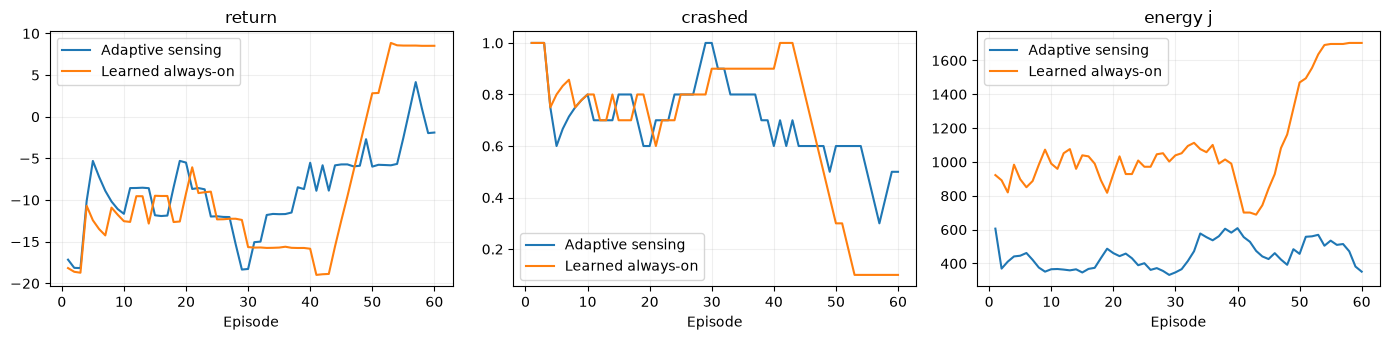

In [4]:
always_on_agent, always_on_history = train_agent(
    config, settings, seed=TRAIN_SEED, modes=("all_on",))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for label, history in [("Adaptive sensing", adaptive_history), ("Learned always-on", always_on_history)]:
    for ax, metric in zip(axes, ["return", "crashed", "energy_j"]):
        rolling = history[metric].astype(float).rolling(min(10, TRAIN_EPISODES), min_periods=1).mean()
        ax.plot(history.episode, rolling, label=label)
        ax.set(xlabel="Episode", title=metric.replace("_", " "))
        ax.grid(alpha=.2)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Evaluate without exploration or learning

All four policies start from the same held-out traffic seeds for each condition:
learned adaptive sensing, learned always-on sensing, fixed IDLE/all-on, and random
driving/all-on. Evaluation uses epsilon=0, breaks value ties with a seeded RNG,
and does not change agent weights.

Report crashes, completion, distance, and sensing power together. **Lower total
energy can simply mean an earlier crash.** Mean power corrects for episode length
but does not establish safety. Total reward also depends on our chosen energy and
confidence penalties. The model can be confidently wrong.

Four seeds per weather condition are an exploratory check. They do not establish
statistical significance. Later use separate validation/test sets and multiple
independent training seeds.

**Interpretation:** lower crash rates can come from slower driving rather than
better sensing. A policy that spends most of its time with sensors off may have
learned a conservative speed pattern. Check sensing-mode use, speed, and actions;
these comparisons do not establish that sensor information caused an improvement.
Here completion means reaching 300 m safely, not surviving a time cutoff.
Compare **completion fraction and crash fraction first**, then completion time
among successful episodes. Failed episodes have missing completion times; a
policy that crashes early must not look fast. Elapsed time includes failures.
Raw return is not comparable with the old notebook because the task changed.
The new discount (0.99 versus 0.95) and task features also change the setup;
this run alone cannot isolate which change caused a behavior difference.


In [5]:
agents = {"adaptive": adaptive_agent, "learned_all_on": always_on_agent,
          "idle_all_on": None, "random_all_on": None}
frozen_weights = adaptive_agent.weights.copy()
evaluation = evaluate_agents(config, agents, TEST_SEEDS, TEST_WEATHER)
assert np.array_equal(frozen_weights, adaptive_agent.weights)
summary = evaluation.groupby("policy", sort=False).agg(
    episodes=("seed", "count"), mean_return=("return", "mean"),
    return_std=("return", "std"), crash_fraction=("crashed", "mean"),
    completion_fraction=("completed", "mean"),
    mean_completion_time_s=("completion_time_s", "mean"),
    mean_elapsed_s=("elapsed_s", "mean"), mean_speed_m_s=("mean_speed_m_s", "mean"), mean_distance_m=("distance_m", "mean"),
    mean_power_w=("mean_power_w", "mean"), mean_energy_j=("energy_j", "mean"),
    mean_uncertainty=("mean_uncertainty", "mean"))
display(summary.round(3))
display(evaluation.groupby(["weather", "policy"], sort=False)[
    ["return", "crashed", "distance_m", "mean_power_w", "mean_uncertainty"]].mean().round(3))

Evaluated clear


Evaluated rain


Evaluated fog


,episodes,mean_return,return_std,crash_fraction,completion_fraction,mean_completion_time_s,mean_elapsed_s,mean_speed_m_s,mean_distance_m,mean_power_w,mean_energy_j,mean_uncertainty
policy,,,,,,,,,,,,
adaptive,12,10.261,8.912,0.083,0.917,14.455,14.000,21.406,297.686,56.106,776.479,0.978
learned_all_on,12,11.527,0.018,0.000,1.000,15.000,15.000,20.354,305.310,123.000,1845.000,0.961
idle_all_on,12,-10.416,14.379,0.750,0.250,12.000,9.875,24.919,246.183,123.000,1214.625,0.963
random_all_on,12,-11.158,14.060,0.750,0.250,14.000,8.500,24.255,196.400,123.000,1045.500,0.967


return  crashed  distance_m  mean_power_w  \
weather policy                                                      
clear   adaptive         5.090     0.25     283.458        68.838   
        learned_all_on  11.523     0.00     305.310       123.000   
        idle_all_on    -10.410     0.75     246.183       123.000   
        random_all_on  -11.156     0.75     196.400       123.000   
rain    adaptive        13.013     0.00     303.241        55.038   
        learned_all_on  11.523     0.00     305.310       123.000   
        idle_all_on    -10.418     0.75     246.183       123.000   
        random_all_on  -11.161     0.75     196.400       123.000   
fog     adaptive        12.679     0.00     306.360        44.442   
        learned_all_on  11.533     0.00     305.310       123.000   
        idle_all_on    -10.419     0.75     246.183       123.000   
        random_all_on  -11.159     0.75     196.400       123.000   

                        mean_uncertainty  
weather policy                            
clear   adaptive                   0.976  
        learned_all_on             0.963  
        idle_all_on                0.956  
        random_all_on              0.965  
rain    adaptive                   0.981  
        learned_all_on             0.963  
        idle_all_on                0.965  
        random_all_on              0.970  
fog     adaptive                   0.978  
        learned_all_on             0.956  
        idle_all_on                0.966  
        random_all_on              0.967

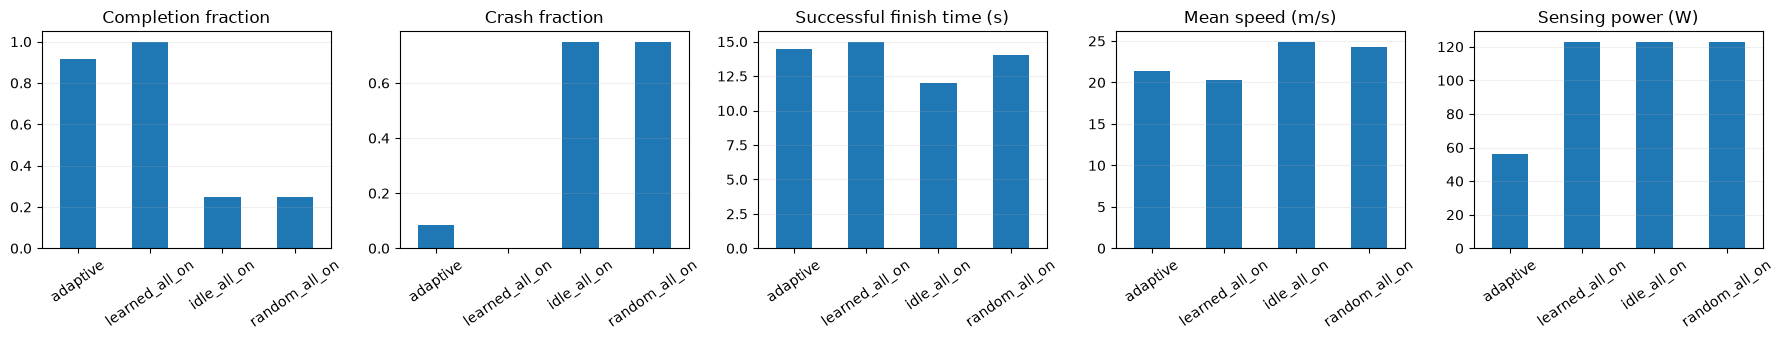

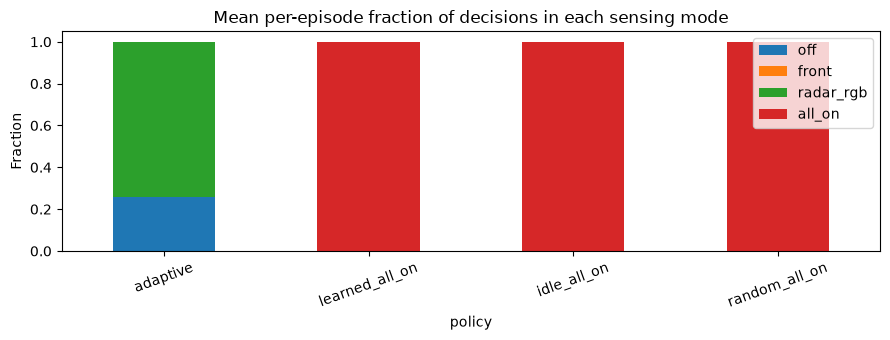

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, metric, title in zip(axes,
        ["completion_fraction", "crash_fraction", "mean_completion_time_s", "mean_speed_m_s", "mean_power_w"],
        ["Completion fraction", "Crash fraction", "Successful finish time (s)", "Mean speed (m/s)", "Sensing power (W)"]):
    summary[metric].plot.bar(ax=ax, rot=35, title=title)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()
fractions = evaluation.groupby("policy", sort=False)[
    ["mode_fraction_off", "mode_fraction_front", "mode_fraction_radar_rgb", "mode_fraction_all_on"]].mean()
fractions.columns = [c.removeprefix("mode_fraction_") for c in fractions.columns]
fractions.plot.bar(stacked=True, figsize=(9, 3.5), rot=20,
                   title="Mean per-episode fraction of decisions in each sensing mode")
plt.ylabel("Fraction")
plt.tight_layout()
plt.show()

## 6. Inspect what the adaptive agent actually does

Watch one held-out scenario. The animation is illustrative; aggregate evaluation
above is the comparison. An initial blind action is expected: reset starts with no
measurements, and choosing sensing now affects only future observations.

Frequent switching can prevent sensors finishing warm-up or cancel pending
measurements. The environment charges active power while warming up. This short
agent has no explicit switching penalty or minimum dwell-time constraint.

seed                           100000
return                      12.688253
driving_return                    0.0
energy_j                       648.35
mean_power_w                43.223333
mean_uncertainty             0.983931
crashed                         False
completed                        True
completion_time_s                15.0
distance_m                 304.871801
elapsed_s                        15.0
mean_speed_m_s              20.324787
steps                              30
mode_fraction_off            0.433333
mode_fraction_front               0.0
mode_fraction_radar_rgb      0.566667
mode_fraction_all_on              0.0
Name: Watched episode, dtype: object

,step,time_s,drive,sensing,reward,energy_j,uncertainty,crashed,driving,energy_penalty,uncertainty_penalty,progress,time_penalty,completion_bonus,early_completion_bonus,failure_penalty
0,1,0.5,IDLE,radar_rgb,0.112803,37.45,0.994932,False,0.0,-0.03745,-0.049747,0.250000,-0.05,0.0,0.0000,0.0
1,2,1.0,SLOWER,off,0.133336,0.90,0.997410,False,0.0,-0.00090,-0.049871,0.234107,-0.05,0.0,0.0000,0.0
2,3,1.5,LANE_RIGHT,radar_rgb,0.074088,37.45,0.979261,False,0.0,-0.03745,-0.048963,0.210501,-0.05,0.0,0.0000,0.0
3,4,2.0,SLOWER,off,0.104673,0.90,0.987147,False,0.0,-0.00090,-0.049357,0.204930,-0.05,0.0,0.0000,0.0
4,5,2.5,IDLE,radar_rgb,0.066447,37.45,0.972358,False,0.0,-0.03745,-0.048618,0.202515,-0.05,0.0,0.0000,0.0
5,6,3.0,SLOWER,off,0.100885,0.90,0.987361,False,0.0,-0.00090,-0.049368,0.201153,-0.05,0.0,0.0000,0.0
6,7,3.5,LANE_RIGHT,radar_rgb,0.059569,37.45,0.971269,False,0.0,-0.03745,-0.048563,0.195582,-0.05,0.0,0.0000,0.0
7,8,4.0,SLOWER,off,0.098850,0.90,0.979846,False,0.0,-0.00090,-0.048992,0.198742,-0.05,0.0,0.0000,0.0
8,9,4.5,IDLE,radar_rgb,0.062841,37.45,0.991508,False,0.0,-0.03745,-0.049575,0.199867,-0.05,0.0,0.0000,0.0
9,10,5.0,SLOWER,off,0.099303,0.90,0.996176,False,0.0,-0.00090,-0.049809,0.200012,-0.05,0.0,0.0000,0.0


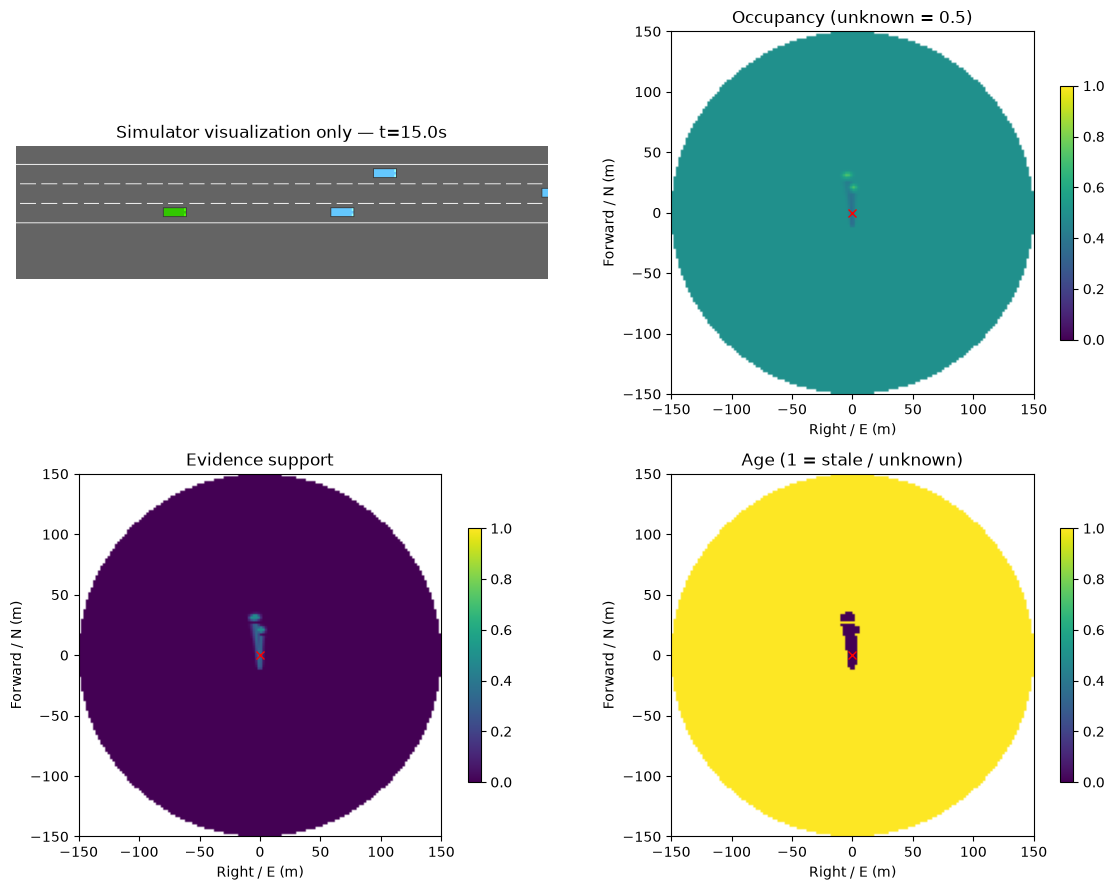

In [7]:
WATCH_SEED = TEST_SEEDS[0]
WATCH_WEATHER = "fog"
watch_config = copy.deepcopy(config)
watch_config.weather.preset = WATCH_WEATHER
watch_metrics, watch = run_agent(watch_config, adaptive_agent, seed=WATCH_SEED, capture=True)
display(pd.Series(watch_metrics, name="Watched episode"))
display(watch.history)
fig = plot_snapshot(watch)
plt.show()

In [8]:
radius = watch.radius_m
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
road_image = axes[0].imshow(watch.frames[0])
axes[0].axis("off")
map_image = axes[1].imshow(np.ma.masked_where(watch.snapshots[0]["valid_cells"] == 0,
    watch.snapshots[0]["grid"][0]), extent=(-radius, radius, -radius, radius), vmin=0, vmax=1)
axes[1].plot(0, 0, "rx")
axes[1].set(xlabel="Right / E (m)", ylabel="Forward / N (m)")
fig.colorbar(map_image, ax=axes[1], shrink=.8)

def update_frame(i):
    road_image.set_data(watch.frames[i])
    obs = watch.snapshots[i]
    map_image.set_data(np.ma.masked_where(obs["valid_cells"] == 0, obs["grid"][0]))
    if i == 0:
        label = "Reset: sensors off, unknown map"
    else:
        row = watch.history.iloc[i - 1]
        label = f"t={row.time_s:.1f}s | {row.drive} | {row.sensing}"
    axes[0].set_title("Simulator visualization only")
    axes[1].set_title(label)
    return road_image, map_image

animation = FuncAnimation(fig, update_frame, frames=len(watch.frames),
                          interval=1000 / config.highway["policy_frequency"], blit=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

## 7. Read the learned action values

These are estimated discounted returns, not safety probabilities. Below we rank
joint actions for the observation after the first decision (or the final available
observation). High values can be wrong with short training or an inadequate
feature representation. This inspection does not update the model.

In [9]:
encoder = ObservationEncoder(config)
INSPECT_INDEX = min(1, len(watch.snapshots) - 1)
values = adaptive_agent.values(encoder(watch.snapshots[INSPECT_INDEX]))
action_values = pd.DataFrame([
    {"drive": drive, "sensing": mode, "estimated_Q": value}
    for (drive, mode), value in zip(adaptive_agent.actions, values)])
display(action_values.sort_values("estimated_Q", ascending=False).reset_index(drop=True).round(3))

,drive,sensing,estimated_Q
0,SLOWER,off,-1.049
1,IDLE,radar_rgb,-1.153
2,LANE_RIGHT,radar_rgb,-1.202
3,LANE_LEFT,off,-1.310
4,SLOWER,front,-1.412
5,FASTER,off,-1.548
6,IDLE,off,-1.552
7,FASTER,radar_rgb,-1.559
8,IDLE,all_on,-1.913
9,SLOWER,all_on,-1.916


## 8. Save this run

This saves both learned models, configuration, learning settings, training curves,
and held-out measurements together. Loading weights requires the same feature
schema, environment configuration, and action menu. A new timestamped directory
is created each time; saved runs are kept under `runs/`.

In [10]:
SAVE_RUN = True
if SAVE_RUN:
    from datetime import datetime
    from zoneinfo import ZoneInfo
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f")
    output = PROJECT_ROOT / "runs/training" / f"time_completion_{stamp}"
    output.mkdir(parents=True, exist_ok=False)
    config.save(output / "config.json")
    adaptive_agent.save(output / "adaptive_agent.npz")
    always_on_agent.save(output / "always_on_agent.npz")
    adaptive_history.to_csv(output / "adaptive_training.csv", index=False)
    always_on_history.to_csv(output / "always_on_training.csv", index=False)
    evaluation.to_csv(output / "evaluation.csv", index=False)
    summary.to_csv(output / "summary.csv")
    watch.history.to_csv(output / "watched_episode.csv", index=False)
    (output / "metadata.json").write_text(json.dumps({
        "algorithm": "linear Expected SARSA", "feature_schema": adaptive_agent.feature_schema,
        "objective": "fixed-distance safe completion with early-finish bonus",
        "settings": asdict(settings), "training_seed": TRAIN_SEED,
        "test_seeds": TEST_SEEDS, "test_weather": TEST_WEATHER,
        "watch_seed": WATCH_SEED, "watch_weather": WATCH_WEATHER,
        "adaptive_actions": adaptive_agent.actions, "always_on_actions": always_on_agent.actions,
        "package_versions": PACKAGE_VERSIONS, "python": sys.version,
    }, indent=2))
    restored = LinearExpectedSarsa.load(output / "adaptive_agent.npz")
    assert np.array_equal(restored.weights, adaptive_agent.weights)
    print("Saved experiment:", output)
else:
    print("Saving disabled")

Saved experiment: runs/training/time_completion_20261101_111935_114914


## Interpretation and next experiments

A faster successful trip earns a larger finish bonus and pays fewer time and
energy costs. Progress is capped at the finish line; collision/off-road takes
precedence over a simultaneous finish. A deadline without a finish is a failure.
No completion bonus is paid for a crash. Failure penalties discourage ending an
episode just to avoid running costs, but these weights are assumptions to study.

Use the saved configuration with these models: the route feature schema differs
from the first experiment. Sixty training episodes and twelve evaluation episodes
per policy remain exploratory. Repeat training seeds and use a separate validation
set for tuning. To isolate reward effects, compare time_weight=0 and
early_completion_bonus=0 with all other route settings and training seeds held
fixed; then sweep time/safety weights. More speed may increase collisions.
